In [1]:
import pandas as pd
print("环境正常")

环境正常


In [2]:
import pandas as pd
import time

start = time.time()
df1 = pd.read_excel("data/online_retail_II.xlsx", sheet_name="Year 2009-2010", engine="openpyxl")
print("读取耗时：", round(time.time() - start, 1), "秒")
print(df1.shape)
print(df1.columns.tolist())

读取耗时： 58.3 秒
(525461, 8)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [3]:
xls = pd.ExcelFile("data/online_retail_II.xlsx", engine="openpyxl")
print("sheet名：", xls.sheet_names)

sheet名： ['Year 2009-2010', 'Year 2010-2011']


In [4]:
df1 = pd.read_excel(
    "data/online_retail_II.xlsx",
    sheet_name="Year 2009-2010",
    engine="openpyxl"
)
print("df1 shape:", df1.shape)
print(df1.head(3))

df1 shape: (525461, 8)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  


In [5]:
df2 = pd.read_excel(
    "data/online_retail_II.xlsx",
    sheet_name="Year 2010-2011",
    engine="openpyxl"
)
print("df2 shape:", df2.shape)

df2 shape: (541910, 8)


In [6]:
df = pd.concat([df1, df2], ignore_index=True)

print("合并后 shape:", df.shape)
print("\n数据类型：")
print(df.dtypes)
print("\n缺失值统计：")
print(df.isnull().sum())
print("\n前3行：")
display(df.head(3))

合并后 shape: (1067371, 8)

数据类型：
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

缺失值统计：
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

前3行：


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom


In [7]:
# 1. 备份原始数据，方便对比
df_clean = df.copy()
raw_rows = len(df_clean)

# 2. 剔除取消/退货单（Invoice 以 'C' 开头）
# 注意：这个数据集的 Invoice 列可能已经是字符串，也可能混杂了整数
df_clean = df_clean[~df_clean['Invoice'].astype(str).str.startswith('C')]

# 3. 剔除缺失 Customer ID 的行（做RFM必须要有客户ID）
df_clean = df_clean.dropna(subset=['Customer ID'])

# 4. 剔除数量 <= 0 或 单价 <= 0 的异常行
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)]

# 5. 把 Customer ID 转成整数（因为已经没缺失值了，不需要带 .0）
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)

# 6. 计算每笔交易的总金额（单价 × 数量）
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

# 7. 从时间列提取“月份”和“小时”（为了后面的趋势图）
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

# 8. 看看清洗结果
clean_rows = len(df_clean)
print(f"清洗前数据量: {raw_rows} 行")
print(f"清洗后数据量: {clean_rows} 行")
print(f"剔除了: {raw_rows - clean_rows} 行 (占比 {((raw_rows - clean_rows) / raw_rows) * 100:.2f}%)")
print("\n清洗后的数据类型：")
print(df_clean.dtypes)

清洗前数据量: 1067371 行
清洗后数据量: 805549 行
剔除了: 261822 行 (占比 24.53%)

清洗后的数据类型：
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             int64
Country                   str
Revenue               float64
Month               period[M]
Hour                    int32
dtype: object


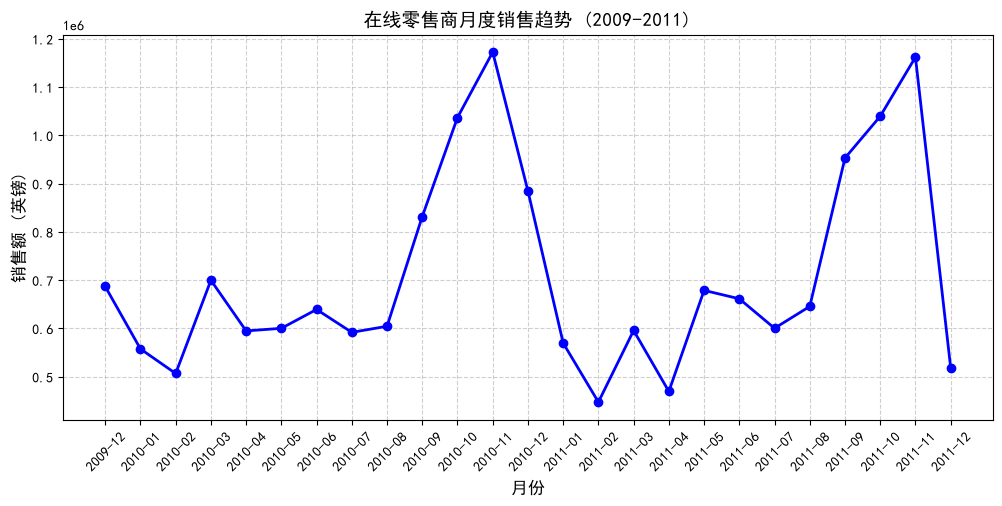

In [8]:
import matplotlib.pyplot as plt

# 1. 设置中文字体（Windows 系统通常用黑体）
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 2. 按月汇总销售额
monthly_sales = df_clean.groupby('Month')['Revenue'].sum()

# 3. 画图
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker='o', color='b', linewidth=2)

# 4. 添加标题和标签
plt.title('在线零售商月度销售趋势 (2009-2011)', fontsize=14)
plt.xlabel('月份', fontsize=12)
plt.ylabel('销售额 (英镑)', fontsize=12)

# 让横坐标的月份倾斜45度，避免重叠
plt.xticks(rotation=45) 
plt.grid(True, linestyle='--', alpha=0.6)

# 保存图片到 images 文件夹
plt.savefig("images/monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

总共 5283 种商品。
前 1131 种商品（占比 21.4%）贡献了 80% 的销售额。


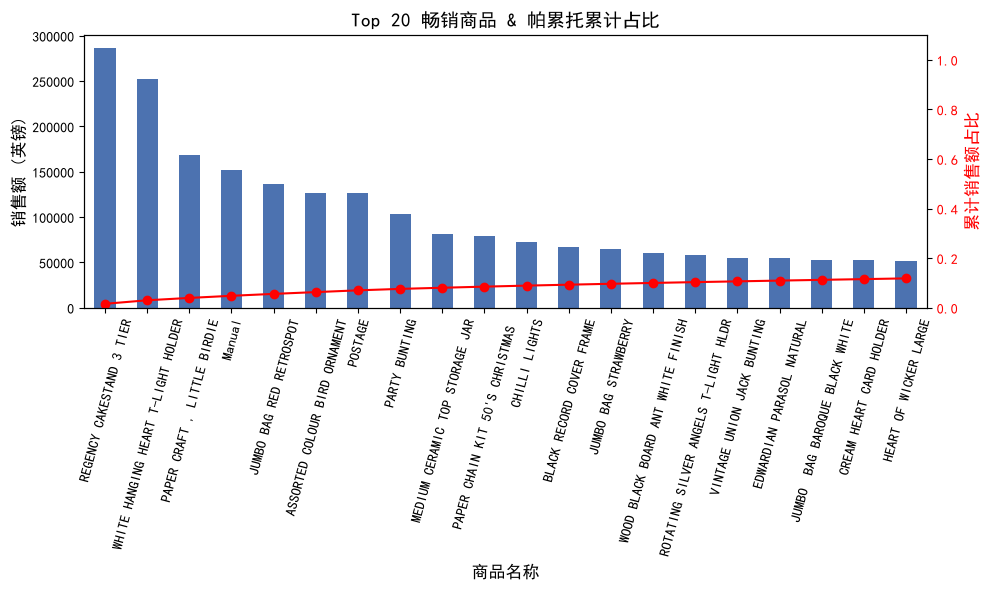

In [9]:
# 1. 按商品名称汇总销售额，降序排列
product_sales = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False)

# 2. 计算累计销售额和累计占比
cum_sales = product_sales.cumsum()
cum_ratio = cum_sales / product_sales.sum()

# 3. 找到累计占比达到 80% 的商品数量
top_80_idx = (cum_ratio <= 0.8).sum()
total_products = len(product_sales)
print(f"总共 {total_products} 种商品。")
print(f"前 {top_80_idx} 种商品（占比 {top_80_idx/total_products*100:.1f}%）贡献了 80% 的销售额。")

# 4. 画图
fig, ax1 = plt.subplots(figsize=(10, 6))

# 柱状图：前 20 个最赚钱的商品
product_sales.head(20).plot(kind='bar', ax=ax1, color='#4c72b0')
ax1.set_ylabel('销售额 (英镑)', fontsize=12)
ax1.set_xlabel('商品名称', fontsize=12)
ax1.set_title('Top 20 畅销商品 & 帕累托累计占比', fontsize=14)
plt.xticks(rotation=75)

# 折线图：累计占比 (用副坐标轴)
ax2 = ax1.twinx()
# 为了让折线图看起来平滑，X轴用商品序号(1到20)
ax2.plot(range(20), cum_ratio.head(20).values, color='red', marker='o', linestyle='-')
ax2.set_ylabel('累计销售额占比', fontsize=12, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 1.1)

plt.tight_layout()
plt.savefig("images/pareto_chart.png", dpi=150, bbox_inches="tight")
plt.show()

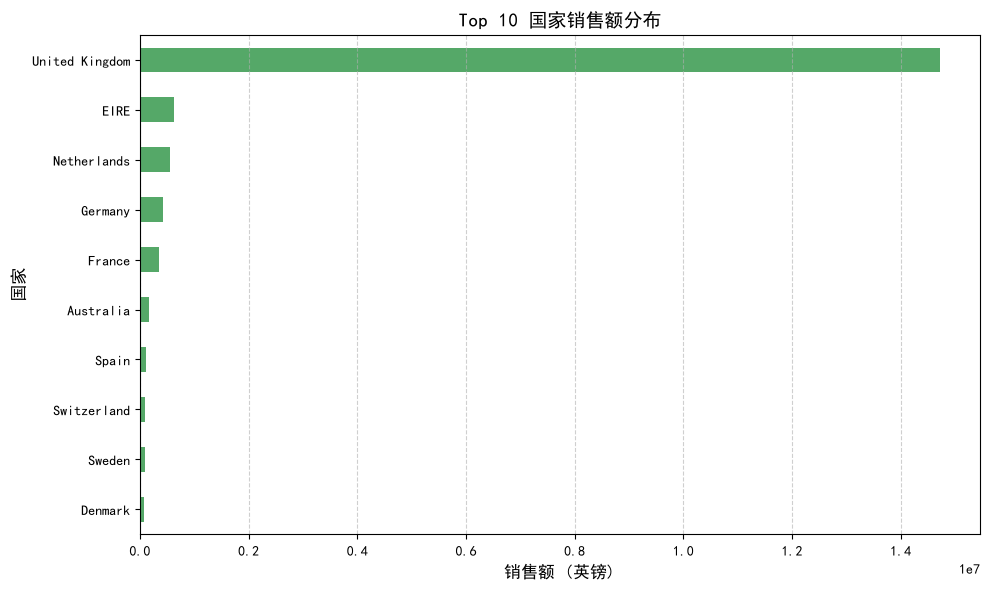

In [10]:
# 1. 按照国家汇总销售额，取前 10 名
country_sales = df_clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)

# 2. 画横向柱状图（因为国家名字比较长，横向放得下）
plt.figure(figsize=(10, 6))
# 倒序排列让最大的在最上面
country_sales.sort_values().plot(kind='barh', color='#55a868')

plt.title('Top 10 国家销售额分布', fontsize=14)
plt.xlabel('销售额 (英镑)', fontsize=12)
plt.ylabel('国家', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("images/country_sales.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
total_revenue = df_clean['Revenue'].sum()
uk_revenue = df_clean[df_clean['Country'] == 'United Kingdom']['Revenue'].sum()
uk_percentage = (uk_revenue / total_revenue) * 100

print(f"英国本土贡献占比: {uk_percentage:.2f}%")

英国本土贡献占比: 82.98%


各客群画像统计：


,客户数,总收入,客户数占比(%),收入贡献占比(%)
Segment,,,,
重要价值客户,1300,12128115.56,22.12,68.35
一般客户,2758,4175305.82,46.92,23.53
重要保持客户,227,1018866.68,3.86,5.74
流失客户,1275,327643.25,21.69,1.85
新客户/潜力客户,318,93497.86,5.41,0.53


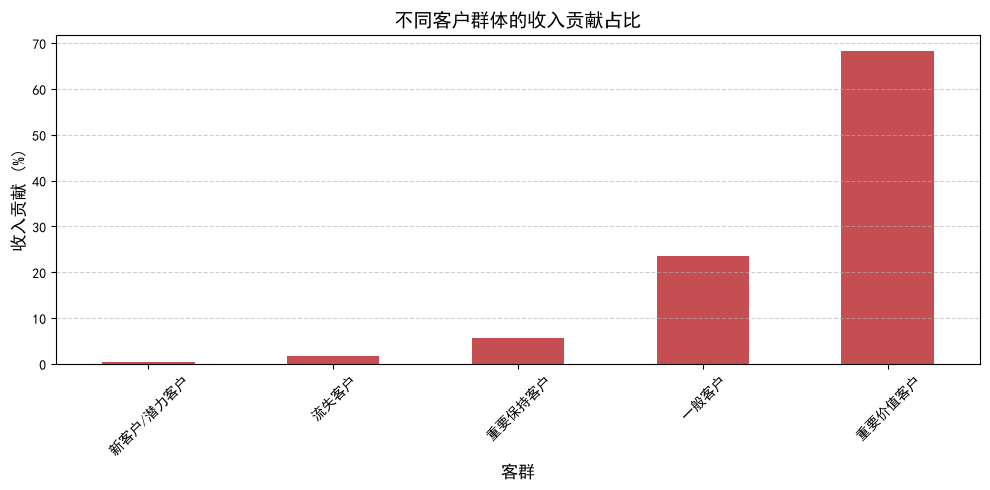

In [12]:
import matplotlib.pyplot as plt
import datetime as dt

# 1. 重新计算 RFM
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
rfm = df_clean.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique',
    'Revenue': 'sum'
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# 2. 打分
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# 3. 打标签
def segment_customer(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4: return '重要价值客户'
    elif r <= 2 and f >= 4 and m >= 4: return '重要保持客户'
    elif r >= 4 and f <= 2 and m <= 2: return '新客户/潜力客户'
    elif r <= 2 and f <= 2 and m <= 2: return '流失客户'
    else: return '一般客户'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

# 4. 统计并画图
segment_stats = rfm.groupby('Segment').agg(
    客户数=('Monetary', 'size'),
    总收入=('Monetary', 'sum')
)
segment_stats['客户数占比(%)'] = (segment_stats['客户数'] / segment_stats['客户数'].sum()) * 100
segment_stats['收入贡献占比(%)'] = (segment_stats['总收入'] / segment_stats['总收入'].sum()) * 100

print("各客群画像统计：")
display(segment_stats.round(2).sort_values('收入贡献占比(%)', ascending=False))

plt.figure(figsize=(10, 5))
segment_stats['收入贡献占比(%)'].sort_values().plot(kind='bar', color='#c44e52')
plt.title('不同客户群体的收入贡献占比', fontsize=14)
plt.xlabel('客群', fontsize=12)
plt.ylabel('收入贡献 (%)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("images/rfm_segment.png", dpi=150, bbox_inches="tight")
plt.show()